In [1]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\Aryan Roshan\Desktop\battery-life-cycle\battery-life-cycle\.venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


imports and project paths

In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from soc.data import split_frames
from soc.features import feature_columns
from soc.metrics import soc_metrics
from soc.models import FNN

print("project root:", ROOT)

project root: C:\Users\Aryan Roshan\Desktop\battery-life-cycle\battery-life-cycle


In [3]:
cfg = yaml.safe_load(open(ROOT / "configs" / "default.yaml"))
data = pd.read_parquet(ROOT / cfg["processed_path"])
splits = split_frames(data, cfg["split"])

for name, df in splits.items():
    print(f"{name:5s}: {df.run_id.nunique()} runs, {len(df):,} rows")

train: 36 runs, 231,428 rows
val  : 5 runs, 35,728 rows
test : 23 runs, 175,874 rows


In [4]:
MODEL_DIR = ROOT / "outputs" / "fnn" / "seed42"
ckpt = torch.load(MODEL_DIR / "model.pt", map_location="cpu", weights_only=False)

cols = ckpt["features"]
mean = np.asarray(ckpt["scaler"]["mean"])
std = np.asarray(ckpt["scaler"]["std"])
mcfg = ckpt["config"]

model = FNN(len(cols), mcfg["hidden"], mcfg.get("dropout", 0))
model.load_state_dict(ckpt["state_dict"])
model.eval()

print("features:", cols)
print("hidden layers:", mcfg["hidden"])

features: ['voltage', 'current', 'temp_c', 'v_avg_30s', 'i_avg_30s', 'v_avg_120s', 'i_avg_120s', 'v_avg_300s', 'i_avg_300s']
hidden layers: [64, 64, 32]


In [5]:
def predict_array(x):
    x = (x - mean) / std
    x = torch.tensor(x, dtype=torch.float32)
    with torch.no_grad():
        return model(x).numpy().reshape(-1)

def predict(df):
    return predict_array(df[cols].to_numpy())

test = splits["test"].copy()
test["soc_pred"] = predict(test)
test["err"] = (test["soc_pred"] - test["soc"]) * 100
test["abs_err"] = test["err"].abs()
test["t_min"] = test["time_s"] / 60

test[["run_id", "t_min", "soc", "soc_pred", "err"]].head()

,run_id,t_min,soc,soc_pred,err
0,n20degC_610_HWFET,0.000000,0.999982,0.992021,-0.796103
1,n20degC_610_HWFET,0.016667,0.999970,0.991063,-0.890720
2,n20degC_610_HWFET,0.033333,0.999952,0.990279,-0.967335
3,n20degC_610_HWFET,0.050000,0.999916,0.989135,-1.078145
4,n20degC_610_HWFET,0.066667,0.999779,0.986001,-1.377791


In [6]:
import json

saved = json.load(open(MODEL_DIR / "metrics.json"))

for t, g in test.groupby("ambient_c"):
    now = soc_metrics(g["soc"], g["soc_pred"])["rmse_pct"]
    before = saved["test_by_temp"][str(t)]["rmse_pct"]
    print(f"{t:>4} °C   now {now:.3f}   saved {before:.3f}")

overall = soc_metrics(test["soc"], test["soc_pred"])["rmse_pct"]
print(f"overall  now {overall:.3f}   saved {saved['test']['rmse_pct']:.3f}")


 -20 °C   now 3.388   saved 3.380
 -10 °C   now 2.256   saved 2.253
   0 °C   now 1.451   saved 1.456
  10 °C   now 1.448   saved 1.456
  25 °C   now 1.592   saved 1.602
  40 °C   now 1.505   saved 1.503
overall  now 1.927   saved 1.928


In [7]:
#confirming the sampling period (data check)
step_s = 1 / cfg["resample_hz"]
print("configured sample period:", step_s, "s")

gaps = test.groupby("run_id")["time_s"].diff().dropna()
print(gaps.value_counts().head())

configured sample period: 1.0 s
time_s
1.0     175820
2.0         29
16.0         1
4.0          1
Name: count, dtype: int64


Section 1: where in the run does the error happen? (10, 25, 40 °C)

In [8]:
def label_segments(df, rest_current=0.05, min_rest_s=60):
    """Split each run into: early 0-5 min, early 5-10 min, middle, rest tail.

    rest tail = final stretch after the last |current| > rest_current,
                counted only if it lasts at least min_rest_s seconds.
    """
    segment = pd.Series("middle", index=df.index)
    for run_id, g in df.groupby("run_id"):
        moving = g[g["current"].abs() > rest_current]
        if moving.empty:
            print(f"WARNING: {run_id} never exceeds {rest_current} A - no rest tail assigned")
            is_rest = pd.Series(False, index=g.index)
        else:
            last_moving_time = moving["time_s"].max()
            is_rest = g["time_s"] > last_moving_time
            rest_duration = g["time_s"].max() - last_moving_time
            if rest_duration < min_rest_s:
                is_rest[:] = False          # too short to count as a rest period
        segment.loc[g.index[is_rest]] = "rest tail"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 10)]] = "early 5-10"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 5)]] = "early 0-5"
    return segment

test["segment"] = label_segments(test)
test["segment"].value_counts()

segment
middle        148292
rest tail      13800
early 5-10      6900
early 0-5       6882
Name: count, dtype: int64

In [9]:
#warm temps only; 25 °C has no HWFET run

WARM = [10, 25, 40]
REF = 25
FIG_DIR = ROOT / "outputs" / "diagnosis"   # save as warm_*.png
FIG_DIR.mkdir(parents=True, exist_ok=True)

warm = test[test["ambient_c"].isin(WARM)].copy()
print(warm.groupby(["ambient_c", "cycle"])["run_id"].first().to_string())

ambient_c  cycle
10         HWFET    10degC_576_HWFET
           LA92      10degC_582_LA92
           UDDS      10degC_576_UDDS
           US06      10degC_567_US06
25         LA92      25degC_551_LA92
           UDDS      25degC_551_UDDS
           US06      25degC_551_US06
40         HWFET    40degC_556_HWFET
           LA92      40degC_556_LA92
           UDDS      40degC_556_UDDS
           US06      40degC_556_US06

In [10]:
#Checking the final resting period (rest tail) of each warm test run

tail = warm[warm["segment"] == "rest tail"]
check_tail = tail.groupby("run_id").agg(
    tail_samples=("time_s", "size"),
    max_abs_current=("current", lambda s: s.abs().max()),
    soc_change_pts=("soc", lambda s: (s.max() - s.min()) * 100),
)
print(check_tail.round(3).to_string())
print("\nruns with no rest tail:", sorted(set(warm["run_id"]) - set(check_tail.index)))

                  tail_samples  max_abs_current  soc_change_pts
run_id                                                         
10degC_567_US06            600              0.0             0.0
10degC_576_HWFET           600              0.0             0.0
10degC_576_UDDS            600              0.0             0.0
10degC_582_LA92            600              0.0             0.0
25degC_551_LA92            600              0.0             0.0
25degC_551_UDDS            600              0.0             0.0
25degC_551_US06            600              0.0             0.0
40degC_556_HWFET           600              0.0             0.0
40degC_556_LA92            600              0.0             0.0
40degC_556_UDDS            600              0.0             0.0
40degC_556_US06            600              0.0             0.0

runs with no rest tail: []


In [11]:
#Error per segment, warm temps (and per cycle)

ORDER = ["early 0-5", "early 5-10", "middle", "rest tail"]

def seg_table(df, by):
    rows = []
    for key, g in df.groupby(by):
        total_sq = (g["err"] ** 2).sum()
        for s in ORDER:
            h = g[g["segment"] == s]
            rows.append({by: key, "segment": s,
                         "minutes": len(h) * step_s / 60,
                         "rmse": np.sqrt((h["err"] ** 2).mean()),
                         "mean_signed": h["err"].mean(),
                         "share_%": 100 * (h["err"] ** 2).sum() / total_sq})
    return pd.DataFrame(rows)

seg = seg_table(warm, "ambient_c")

def show(tab, idx, value, title, digits=2):
    print(title)
    print(tab.pivot(index=idx, columns="segment", values=value)[ORDER].round(digits))
    print()

show(seg, "ambient_c", "rmse", "RMSE per segment (SOC points)")
show(seg, "ambient_c", "share_%", "Share of each temperature's total squared error (%)", 1)
show(seg, "ambient_c", "mean_signed", "Mean signed error (+ = over-estimate, - = under-estimate)")

seg_run = seg_table(warm, "run_id")
show(seg_run, "run_id", "rmse", "RMSE per segment, per warm run")
show(seg_run, "run_id", "mean_signed", "Mean signed error per segment, per warm run")

RMSE per segment (SOC points)
segment    early 0-5  early 5-10  middle  rest tail
ambient_c                                          
10              2.17        1.96    1.39       1.37
25              2.04        1.40    1.58       1.62
40              2.71        2.24    1.42       1.28

Share of each temperature's total squared error (%)
segment    early 0-5  early 5-10  middle  rest tail
ambient_c                                          
10               8.0         6.6    78.9        6.5
25               4.9         2.3    86.6        6.2
40              11.0         7.5    76.6        4.9

Mean signed error (+ = over-estimate, - = under-estimate)
segment    early 0-5  early 5-10  middle  rest tail
ambient_c                                          
10             -2.12       -1.61   -0.13      -1.09
25             -2.01       -1.22   -0.73      -1.46
40             -2.69       -1.97   -0.80      -1.07

RMSE per segment, per warm run
segment           early 0-5  early 5-10  middl

In [12]:
#voltage relaxation vs prediction drift during rest (warm temps)

rows = []
for run_id, g in warm[warm["segment"] == "rest tail"].groupby("run_id"):
    g = g.sort_values("time_s")
    rows.append({
        "run_id": run_id,
        "ambient_c": g["ambient_c"].iloc[0],
        "v_rise_mV": (g["voltage"].iloc[-1] - g["voltage"].iloc[0]) * 1000,
        "pred_start_%": g["soc_pred"].iloc[0] * 100,
        "pred_end_%": g["soc_pred"].iloc[-1] * 100,
        "pred_drift_pts": (g["soc_pred"].iloc[-1] - g["soc_pred"].iloc[0]) * 100,
        "true_soc_%": g["soc"].mean() * 100,
    })
relax = pd.DataFrame(rows).sort_values(["ambient_c", "run_id"])

print(relax.round(2).to_string(index=False))
print("\nAverage per temperature:")
print(relax.groupby("ambient_c")[["v_rise_mV", "pred_drift_pts"]].mean().round(2))
print("\nCorrelation between voltage rise and prediction drift:",
      round(relax["v_rise_mV"].corr(relax["pred_drift_pts"]), 2))

          run_id  ambient_c  v_rise_mV  pred_start_%  pred_end_%  pred_drift_pts  true_soc_%
 10degC_567_US06         10     190.37          5.59        2.79           -2.80         5.0
10degC_576_HWFET         10     106.65          6.35        4.13           -2.22         5.0
 10degC_576_UDDS         10      37.88          4.27        3.65           -0.61         5.0
 10degC_582_LA92         10     135.81          5.10        3.51           -1.59         5.0
 25degC_551_LA92         25     108.77          3.84        3.27           -0.57         5.0
 25degC_551_UDDS         25      87.38          4.66        3.04           -1.62         5.0
 25degC_551_US06         25     161.88          6.08        3.48           -2.60         5.0
40degC_556_HWFET         40      91.04          5.85        3.88           -1.97         5.0
 40degC_556_LA92         40      60.11          4.55        3.48           -1.06         5.0
 40degC_556_UDDS         40     115.11          4.32        3.39      

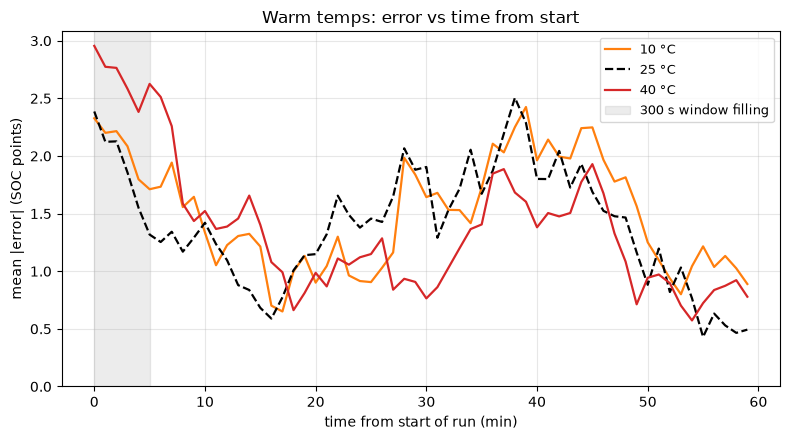

In [13]:
#error vs time from start, warm temps

color_of = {10: "tab:orange", 25: "black", 40: "tab:red"}

def error_curve(t, cycle=None):
    """Mean |error| per 1-min bin (no rest tail, first 60 min)."""
    g = warm[(warm["ambient_c"] == t) & (warm["segment"] != "rest tail") & (warm["t_min"] < 60)]
    if cycle:
        g = g[g["cycle"] == cycle]
    return g, g.groupby(g["t_min"].floordiv(1))["abs_err"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
for t in WARM:
    _, binned = error_curve(t)
    ax.plot(binned.index, binned.values, color=color_of[t],
            ls="--" if t == REF else "-", lw=1.6, label=f"{t} °C")
ax.axvspan(0, 5, color="grey", alpha=0.15, label="300 s window filling")
ax.set_ylim(bottom=0)
ax.set_xlabel("time from start of run (min)")
ax.set_ylabel("mean |error| (SOC points)")
ax.set_title("Warm temps: error vs time from start")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "warm_error_vs_time.png", dpi=150)
plt.show()

In [14]:
#MAE first 5 min vs 5-60 min, per temp and per cycle

summary_rows = []
for (t, cyc), g in warm[(warm["segment"] != "rest tail") & (warm["t_min"] < 60)].groupby(["ambient_c", "cycle"]):
    early_mae = g.loc[g["t_min"] < 5, "abs_err"].mean()
    later_mae = g.loc[g["t_min"] >= 5, "abs_err"].mean()
    summary_rows.append({"ambient_c": t, "cycle": cyc,
                         "MAE first 5 min": early_mae,
                         "MAE 5-60 min": later_mae,
                         "ratio early/later": early_mae / later_mae,
                         "signed first 5 min": g.loc[g["t_min"] < 5, "err"].mean()})
early_vs_later = pd.DataFrame(summary_rows).set_index(["ambient_c", "cycle"])
print(early_vs_later.round(3).to_string())
print("\nper temp (mean of cycles):")
print(early_vs_later.groupby("ambient_c").mean().round(3))

                 MAE first 5 min  MAE 5-60 min  ratio early/later  signed first 5 min
ambient_c cycle                                                                      
10        HWFET            2.217         0.845              2.624              -2.217
          LA92             2.375         1.091              2.177              -2.375
          UDDS             2.221         1.835              1.210              -2.221
          US06             1.690         2.160              0.783              -1.690
25        LA92             2.011         1.026              1.960              -2.011
          UDDS             2.093         1.685              1.243              -2.093
          US06             1.922         1.398              1.375              -1.922
40        HWFET            2.512         0.970              2.590              -2.512
          LA92             2.837         1.017              2.789              -2.837
          UDDS             2.729         1.607        